# Challenge 2 · Razonamiento, espacio de estados y búsqueda
**Caso:** Tipo A — Minería de asteroides.

**Problema:** seleccionar hasta 3 misiones que maximicen la suma del beneficio esperado ajustado por riesgo, sujeto a presupuesto de 700 millones USD.

**Datos:** sintéticos. Los valores son académicos y no deben interpretarse como valuaciones reales.

**Nota:** para abrir desde Colab, cargar este notebook desde GitHub o subirlo manualmente. El CSV está en `data/` y el notebook en `notebooks/`. La función de carga permite usarlo desde un clon del repositorio o desde Colab con URL de GitHub. Antes de ejecutar desde Colab, configurar `GITHUB_USUARIO` y `REPOSITORIO` en la celda siguiente si no se clonó el repositorio.

## Vinculación con el examen parcial Tipo A

El examen pregunta si conviene **invertir masivamente** en minería de asteroides; este cuaderno no presupone que sí. Se propone una **evaluación gradual de inversiones**, usando escenarios de ocho candidatos, presupuesto hipotético de 700 MUSD y hasta tres misiones. Se simula el problema empresarial sin afirmar viabilidad real. El diagrama empresarial y el razonamiento abductivo se documentan en `docs/vinculo_examen.md`.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

GITHUB_USUARIO = "TU_USUARIO"  # Reemplazar para ejecutar directamente en Colab
REPOSITORIO = "ml-mineria-asteroides"
archivo = Path("data/asteroides_sinteticos.csv")
if not archivo.exists():
    archivo = Path("../data/asteroides_sinteticos.csv")
if archivo.exists():
    df = pd.read_csv(archivo)
else:
    if GITHUB_USUARIO == "TU_USUARIO":
        raise FileNotFoundError("Clona el repositorio, sube el CSV a Colab, o configura GITHUB_USUARIO.")
    url = f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{REPOSITORIO}/main/data/asteroides_sinteticos.csv"
    df = pd.read_csv(url)
print(f"Asteroides disponibles: {len(df)}")
display(df.head())

Asteroides disponibles: 220


,asteroide_id,distancia_millones_km,masa_millones_ton,concentracion_metal_pct,costo_mision_musd,riesgo_operacional,beneficio_neto_musd
0,AST-001,91.72,13.09,65.03,158.71,0.214,-19.85
1,AST-002,57.20,20.31,18.40,311.64,0.291,-190.97
2,AST-003,100.44,27.02,57.22,136.90,0.424,276.56
3,AST-004,83.83,38.29,20.93,111.20,0.237,518.90
4,AST-005,21.70,12.53,26.14,175.48,0.129,-57.55


## 1. Representación formal del problema
- **Estado** `s=(i, seleccionados, costo_acumulado, utilidad_acumulada)`: indica que ya se han evaluado los primeros `i` candidatos.
- **Estado inicial:** `(0, (), 0, 0)`.
- **Operadores:** `incluir(i)` o `descartar(i)` el próximo asteroide.
- **Restricciones:** costo total ≤ 700 MUSD, máximo 3 misiones, sin asteroides duplicados.
- **Estado objetivo:** `i=N`, cuando todas las alternativas han sido consideradas.
- **Función objetivo:** maximizar `Σ[beneficio_neto_estimado × (1 - riesgo_operacional)]`.

Para separar los objetivos: este notebook demuestra búsqueda sobre los **beneficios de un escenario sintético conocidos** (oráculo didáctico); el Notebook 02 estima los beneficios con ML. En un caso real, sustituir el beneficio conocido por predicciones entrenadas solo con datos históricos.

In [2]:
# Ocho candidatos para que el árbol de búsqueda sea interpretable y verificable.
candidatos = df.sample(n=8, random_state=8).reset_index(drop=True).copy()
candidatos["utilidad_ajustada_musd"] = (candidatos["beneficio_neto_musd"] * (1 - candidatos["riesgo_operacional"]))
# Solo seleccionar misiones con rentabilidad sintética positiva: evitar penalizarse al tomar negativos.
cols = ["asteroide_id", "costo_mision_musd", "riesgo_operacional", "beneficio_neto_musd", "utilidad_ajustada_musd"]
display(candidatos[cols].round(2))

,asteroide_id,costo_mision_musd,riesgo_operacional,beneficio_neto_musd,utilidad_ajustada_musd
0,AST-117,244.78,0.31,-444.92,-308.77
1,AST-162,238.64,0.32,431.47,294.69
2,AST-168,147.82,0.36,319.75,204.32
3,AST-207,306.39,0.36,-315.45,-203.15
4,AST-206,315.99,0.35,416.98,271.87
5,AST-163,163.69,0.31,518.22,356.54
6,AST-070,219.02,0.19,-407.15,-331.42
7,AST-102,127.61,0.38,178.00,110.89


## 2. Exploración y búsqueda sistemática
Se utiliza búsqueda en anchura (BFS) sobre decisiones binarias (tomar/no tomar), con poda de ramas que incumplen el presupuesto o el máximo de misiones. Al explorar todas las combinaciones factibles, el mejor estado terminal es **óptimo dentro de los ocho candidatos seleccionados**, aunque este método no escala bien para miles de asteroides.

In [3]:
PRESUPUESTO = 700.0
MAX_MISIONES = 3
# (indice, tupla indices, costo, utilidad)
inicial = (0, tuple(), 0.0, 0.0)
cola = deque([inicial])
visitados = 0
podados = 0
terminales = []
profundidades = {i: 0 for i in range(len(candidatos) + 1)}
while cola:
    i, elegidos, costo, utilidad = cola.popleft()
    visitados += 1
    profundidades[i] += 1
    if i == len(candidatos):
        terminales.append((elegidos, costo, utilidad))
        continue
    cola.append((i+1, elegidos, costo, utilidad))  # descartar
    nuevo_costo = costo + float(candidatos.loc[i, "costo_mision_musd"])
    if nuevo_costo <= PRESUPUESTO and len(elegidos) < MAX_MISIONES:
        nuevo_beneficio = utilidad + float(candidatos.loc[i, "utilidad_ajustada_musd"])
        cola.append((i+1, elegidos+(i,), nuevo_costo, nuevo_beneficio))
    else:
        podados += 1
mejor = max(terminales, key=lambda estado: estado[2])
ids = candidatos.iloc[list(mejor[0])]["asteroide_id"].tolist()
print('Estados visitados:', visitados)
print('Ramas podadas:', podados)
print('Estados terminales:', len(terminales))
print('Misiones óptimas:', ids)
print(f'Costo: {mejor[1]:.2f} MUSD / {PRESUPUESTO:.0f} MUSD')
print(f'Utilidad ajustada total: {mejor[2]:.2f} MUSD')
assert mejor[1] <= PRESUPUESTO and len(mejor[0]) <= MAX_MISIONES

Estados visitados: 198
Ramas podadas: 51
Estados terminales: 74
Misiones óptimas: ['AST-162', 'AST-168', 'AST-163']
Costo: 550.15 MUSD / 700 MUSD
Utilidad ajustada total: 855.55 MUSD


## 3. Visualización de exploración y resultado

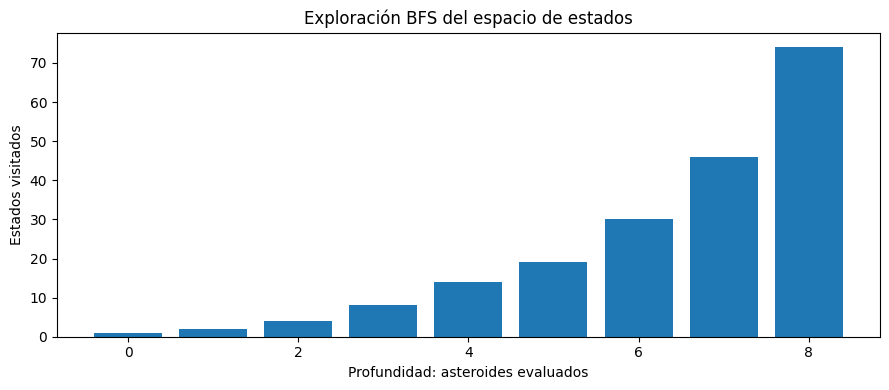

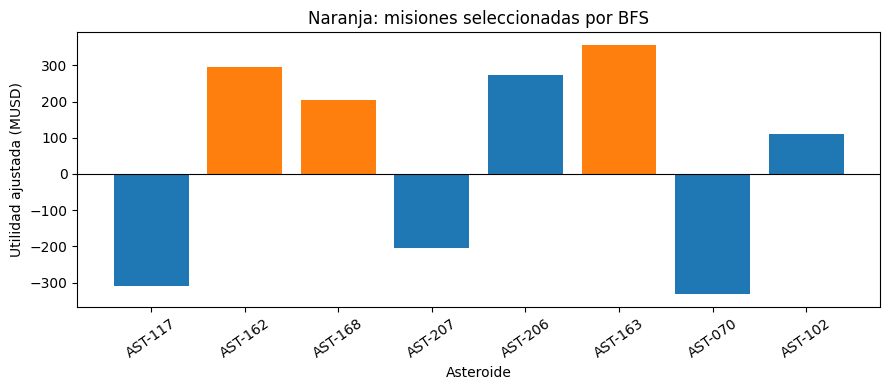

In [4]:
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(list(profundidades.keys()), list(profundidades.values()))
ax.set(xlabel="Profundidad: asteroides evaluados",ylabel="Estados visitados",title="Exploración BFS del espacio de estados")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9,4))
ax.bar(candidatos["asteroide_id"], candidatos["utilidad_ajustada_musd"],
       color=["tab:orange" if i in mejor[0] else "tab:blue" for i in range(len(candidatos))])
ax.axhline(0,color="black",linewidth=.8)
ax.set(xlabel="Asteroide",ylabel="Utilidad ajustada (MUSD)",title="Naranja: misiones seleccionadas por BFS")
plt.xticks(rotation=35); plt.tight_layout(); plt.show()

## 4. Interpretación
La búsqueda considera tanto misiones seleccionadas como descartadas, cumple las restricciones y devuelve la combinación con mayor utilidad sintética ajustada. Su límite principal es la complejidad exponencial, `O(2^N)` en el peor caso. El modelo predictivo independiente del Notebook 02 ilustra cómo estimar los valores cuando todavía no son conocidos.